# 07_results：Holdout（只跑一次）、總表、推論與診斷

設定與協定見 `setup.yaml`；程式在 `src/s07_holdout.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s07_holdout
    s07_holdout.main("reproduction run" if (R / "HOLDOUT_TOUCHED.json").exists() else None)

[{'time': '2026-11-07 01:39:38', 'git_commit': '41aa5e5', 'setup_sha256': '91f31468dad5', 'holdout': ['2024-11-01', '2026-10-30'], 'reason': 'first and only planned run'}]


**07_headline**

,階段,指標,驗證（2012-01 ~ 2024-10）,holdout（2024-11 ~ 2026-10）,基準
0,訊號,每日 IC [HAC 95% CI]、ICIR、IC 為正的 fold 比例,"0.107 [0.086, 0.128]；ICIR 0.62；正 fold 100%","0.028 [-0.024, 0.079]；ICIR 0.16；正 fold 50%",—
1,投組,毛 Sharpe [CI]、MDD、年換手（雙向）,"1.43 [0.85, 2.00]；MDD -33%；換手 10.7×","0.98 [-0.46, 2.42]；MDD -26%；換手 12.3×",0050 1.73（MDD -27%）；池等權 0.69（holdout）；0050 0.9...
2,成本,假設成本下淨 Sharpe；兩平成本（bp／邊，對零／對 0050）,1.19；213／75,0.79；195／-240,—
3,風險覆蓋,有覆蓋時淨 Sharpe 與 MDD,波動目標：1.20，MDD -24%,波動目標：0.79，MDD -23%,—
4,推論,Deflated Sharpe（N = 42）、最短紀錄（年）,0.95；4.4,0.55；9.9,—


decay or sign-flip（holdout IC 的 CI 含 0 或為負）


**07_ic**

,模型｜期間,IC,lo,hi,t,p,ICIR,days,N_eff,folds,正 IC fold 比例
0,rule｜驗證,-0.018564,-0.033835,-0.003293,-2.382604,1.719067e-02,-0.132869,3102.0,155.1,25.0,0.76
1,ridge｜驗證,0.091013,0.067154,0.114872,7.476665,7.616130e-14,0.483741,3102.0,155.1,25.0,0.92
2,lgbm｜驗證,0.106816,0.085697,0.127936,9.913104,0.000000e+00,0.624294,3102.0,155.1,25.0,1.00
3,ensemble｜驗證,0.093692,0.071306,0.116078,8.203144,2.220446e-16,0.527755,3102.0,155.1,25.0,1.00
4,rule｜holdout,0.032336,-0.009193,0.073866,1.526128,1.269780e-01,0.214074,462.0,23.1,4.0,0.50
5,ridge｜holdout,0.057357,0.006626,0.108087,2.215983,2.669269e-02,0.359705,462.0,23.1,4.0,0.75
6,lgbm｜holdout,0.027701,-0.023918,0.079319,1.051815,2.928846e-01,0.163154,462.0,23.1,4.0,0.50
7,ensemble｜holdout,0.063912,0.023687,0.104137,3.114195,1.844476e-03,0.489137,462.0,23.1,4.0,1.00


... (22 outputs left out)

**08_feature_ic**

,特徵,驗證 IC,驗證 lo,驗證 hi,holdout IC,holdout lo,holdout hi,變化
0,peer_ret20,-0.018806,-0.033978,-0.003634,0.032336,-0.009193,0.073866,0.051143
1,peer_ret60,-0.022430,-0.040351,-0.004509,-0.015579,-0.076894,0.045736,0.006851
2,peer_gap20,0.015654,0.006130,0.025178,0.009466,-0.012223,0.031156,-0.006188
3,leader_ret20,-0.017148,-0.029939,-0.004357,0.034787,-0.001831,0.071404,0.051934
4,peer_tight,-0.026283,-0.041737,-0.010829,0.026421,-0.028095,0.080936,0.052704
5,ret20,-0.027497,-0.041791,-0.013203,0.001857,-0.037691,0.041405,0.029354
6,rev5,-0.009384,-0.017365,-0.001403,-0.000274,-0.024039,0.023492,0.009110
7,near_high250,0.049021,0.026384,0.071658,0.034407,-0.007950,0.076764,-0.014614
8,vol60,-0.071660,-0.096793,-0.046527,-0.037805,-0.114812,0.039201,0.033855
9,max_ret20,-0.065315,-0.082578,-0.048052,-0.039806,-0.096341,0.016730,0.025509


**08_holdout_regime_ic**

,狀態,日數,IC,lo,hi
0,中波動,162,0.050250,-0.020289,0.120790
1,高波動,300,0.015524,-0.051409,0.082457
2,多頭,396,0.012780,-0.043225,0.068785
3,空頭,66,0.117224,0.041583,0.192866


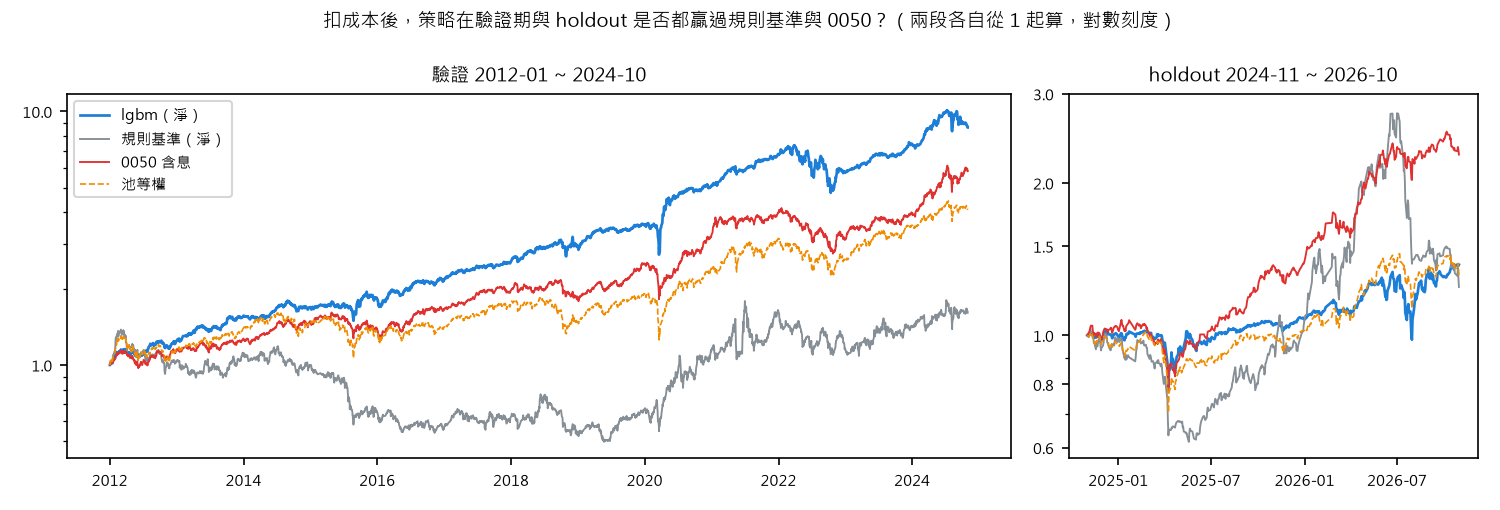

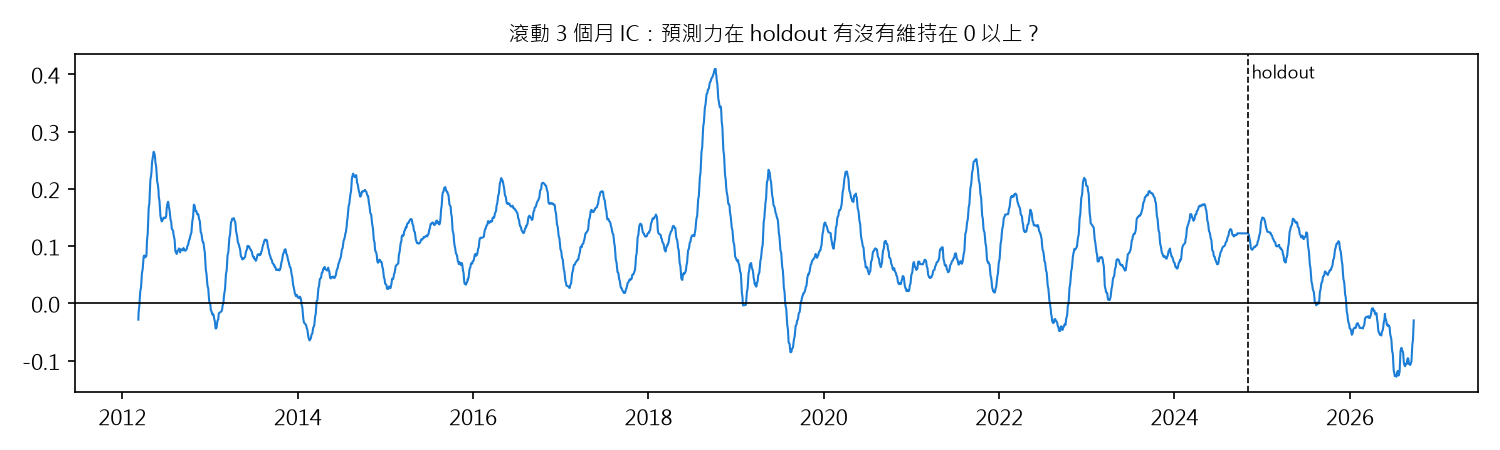

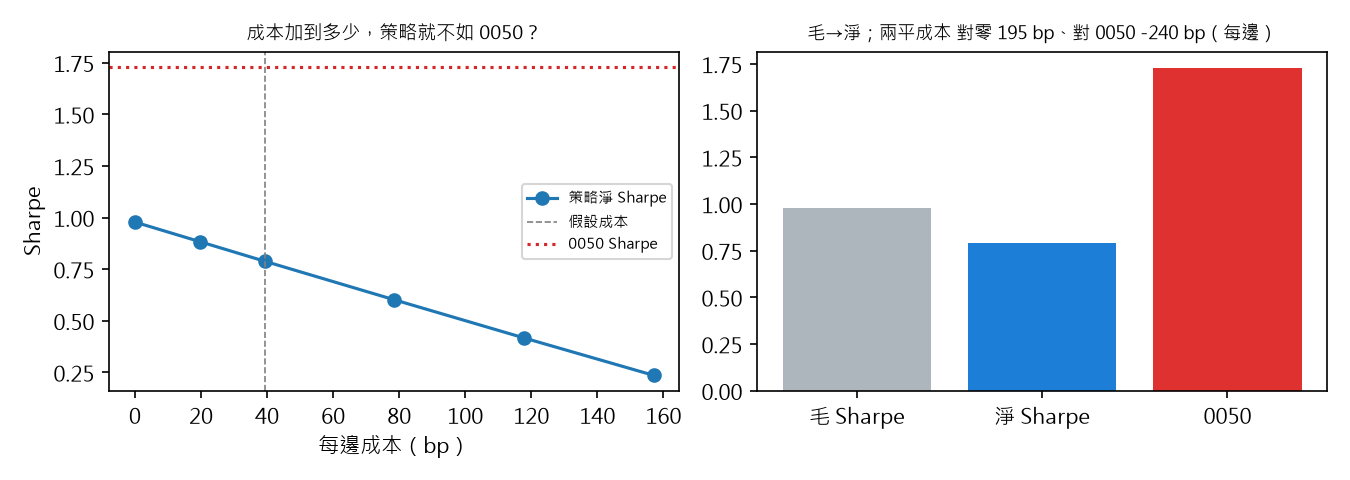

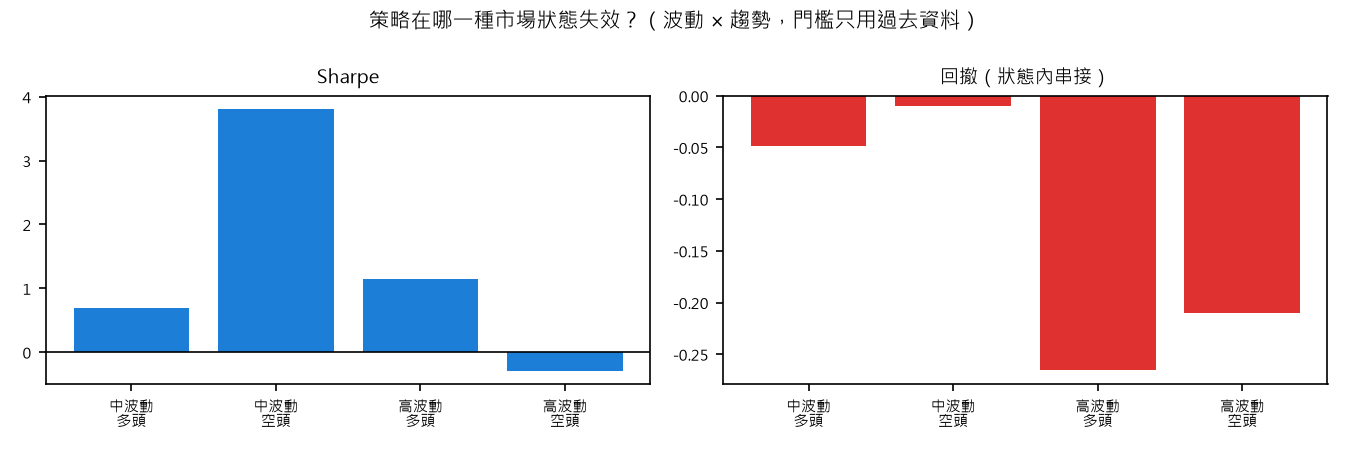

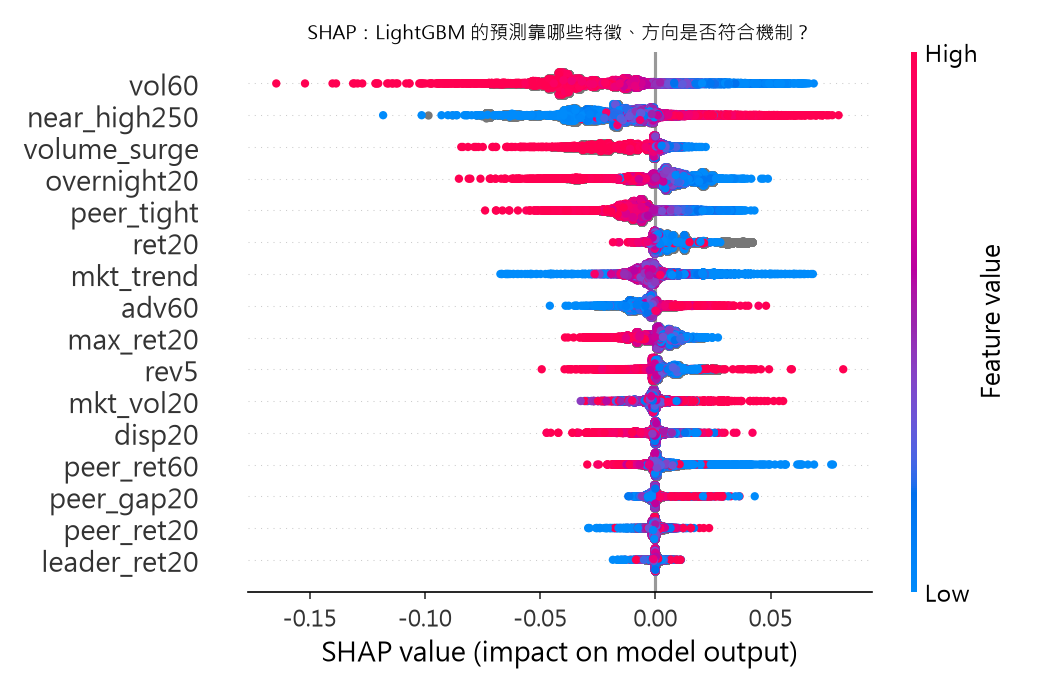

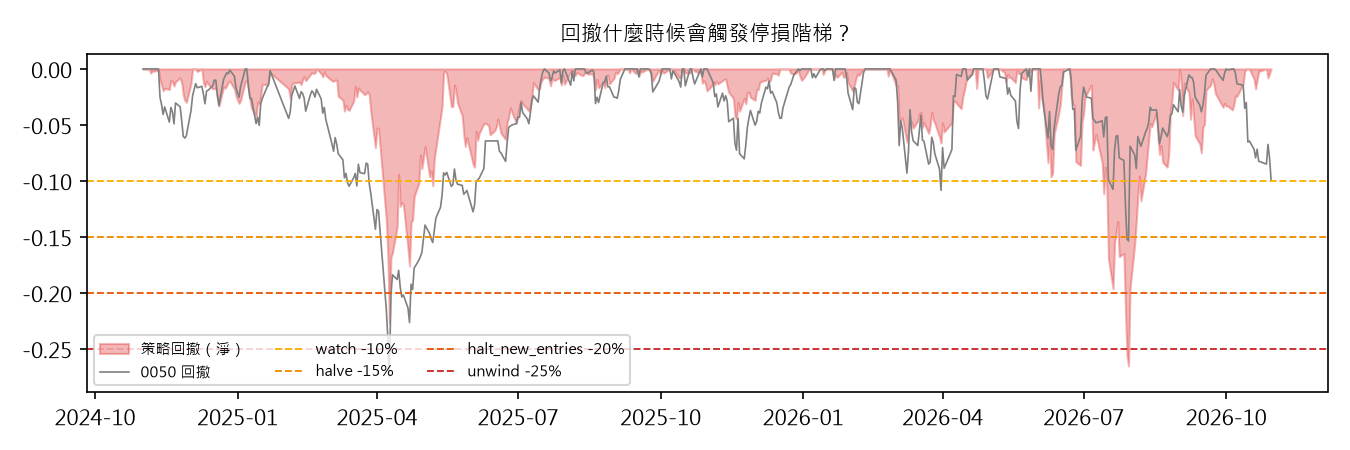

In [3]:
print(json.loads((R / "HOLDOUT_TOUCHED.json").read_text(encoding="utf-8")))
show("07_headline")
print((R / "07_pattern.txt").read_text(encoding="utf-8"))
for t in ("ic", "inference", "attrition", "drift", "regime_mix", "psi", "yearly", "ho_main", "ho_breakeven", "ho_phases", "ho_stress", "ho_killswitch"): show(f"07_{t}")
show("08_feature_ic"); show("08_holdout_regime_ic")
fig("07_equity.png"); fig("07_rolling_ic.png"); fig("07_ho_cost.png"); fig("07_ho_regime.png"); fig("04_shap.png", 650); fig("07_ho_drawdown.png")